# Tarea 13 — Bloom Filter

**Pregunta:** ¿Es posible detectar con poca memoria si un postor ya había participado anteriormente en algún proceso de contratación?

Cada participación se procesa cronológicamente. Antes de insertar el RUC correspondiente al evento actual, se consulta el Bloom Filter:

- `True`: el postor posiblemente ya apareció.
- `False`: el postor definitivamente no había aparecido.

Para evaluar la estructura se mantiene paralelamente un conjunto exacto (`set`) utilizado exclusivamente como *ground truth*.

Se medirán falsos positivos, falsos negativos, memoria y tiempo de procesamiento.

In [1]:
from pathlib import Path
import hashlib
import math
import time

from pyspark.sql import SparkSession, functions as F

In [2]:
spark = (
    SparkSession.builder
    .master("local[*]")
    .appName("SEACE-Bloom")
    .config("spark.driver.memory", "8g")
    .getOrCreate()
)

spark.sparkContext.setLogLevel("ERROR")

PROJECT_ROOT = Path.home() / "dm"
DATA_DIR = PROJECT_ROOT / "parquet"
ARTIFACTS_DIR = PROJECT_ROOT / "artifacts" / "bloom"

ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)

26/10/04 19:08:17 WARN Utils: Your hostname, willian-pc resolves to a loopback address: 127.0.1.1; using 192.168.18.28 instead (on interface wlo1)
26/10/04 19:08:17 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/10/04 19:08:18 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
26/10/04 19:08:18 WARN Utils: Service 'SparkUI' could not bind on port 4040. Attempting port 4041.
26/10/04 19:08:18 WARN Utils: Service 'SparkUI' could not bind on port 4041. Attempting port 4042.


In [3]:
procesos = (
    spark.read.parquet(str(DATA_DIR / "procesos"))
    .select("release_id", "fecha_pub")
)

postores = (
    spark.read.parquet(str(DATA_DIR / "postores"))
    .select("release_id", "ruc")
)

In [4]:
stream_postores = (
    postores
    .join(procesos, "release_id", "inner")
    .select("fecha_pub", "release_id", "ruc")
    .orderBy("fecha_pub", "release_id", "ruc")
)

In [5]:
class BloomFilter:
    def __init__(self, m_bits, k_hashes):
        if m_bits <= 0:
            raise ValueError("m_bits debe ser positivo")

        if k_hashes <= 0:
            raise ValueError("k_hashes debe ser positivo")

        self.m = int(m_bits)
        self.k = int(k_hashes)

        # 8 bits por byte
        self.bits = bytearray((self.m + 7) // 8)

    def _indices(self, item):
        """
        Genera k posiciones usando double hashing.
        Solo calculamos un hash de 128 bits por elemento.
        """
        data = str(item).encode("utf-8")

        digest = hashlib.blake2b(
            data,
            digest_size=16
        ).digest()

        h1 = int.from_bytes(digest[:8], "big")
        h2 = int.from_bytes(digest[8:], "big")

        # Evitar incremento 0
        if h2 == 0:
            h2 = 1

        for i in range(self.k):
            yield (h1 + i * h2) % self.m

    def add(self, item):
        for idx in self._indices(item):
            byte_idx = idx // 8
            bit_idx = idx % 8

            self.bits[byte_idx] |= (1 << bit_idx)

    def contains(self, item):
        for idx in self._indices(item):
            byte_idx = idx // 8
            bit_idx = idx % 8

            if not (
                self.bits[byte_idx] & (1 << bit_idx)
            ):
                return False

        return True

    @property
    def memory_bytes(self):
        return len(self.bits)

In [6]:
bf_test = BloomFilter(
    m_bits=1000,
    k_hashes=3
)

bf_test.add("20123456789")

print(
    "Elemento insertado:",
    bf_test.contains("20123456789")
)

print(
    "Elemento no insertado:",
    bf_test.contains("20999999999")
)

print(
    "Memoria:",
    bf_test.memory_bytes,
    "bytes"
)

Elemento insertado: True
Elemento no insertado: False
Memoria: 125 bytes


In [7]:
n_esperado = 226_293
p_objetivo = 0.01

m_bits = math.ceil(
    -(n_esperado * math.log(p_objetivo))
    / (math.log(2) ** 2)
)

k_hashes = round(
    (m_bits / n_esperado)
    * math.log(2)
)

print("RUC esperados:", n_esperado)
print("FPR objetivo:", p_objetivo)
print("m bits:", m_bits)
print("k hashes:", k_hashes)
print(
    "Memoria teórica:",
    round(m_bits / 8 / 1024, 2),
    "KiB"
)

RUC esperados: 226293
FPR objetivo: 0.01
m bits: 2169032
k hashes: 7
Memoria teórica: 264.77 KiB


In [8]:
bloom = BloomFilter(
    m_bits=m_bits,
    k_hashes=k_hashes
)

vistos_exactos = set()

tp = 0
tn = 0
fp = 0
fn = 0

inicio = time.perf_counter()

for row in stream_postores.select("ruc").toLocalIterator():

    ruc = row["ruc"]

    real_ya_visto = ruc in vistos_exactos
    bloom_ya_visto = bloom.contains(ruc)

    if bloom_ya_visto and real_ya_visto:
        tp += 1

    elif bloom_ya_visto and not real_ya_visto:
        fp += 1

    elif not bloom_ya_visto and not real_ya_visto:
        tn += 1

    else:
        fn += 1

    bloom.add(ruc)
    vistos_exactos.add(ruc)

fin = time.perf_counter()

tiempo_segundos = fin - inicio

[Stage 14:>                                                         (0 + 1) / 1]

In [9]:
fpr_observado = fp / (fp + tn)

print("=== BLOOM FILTER BASELINE ===")
print("TP:", tp)
print("TN:", tn)
print("FP:", fp)
print("FN:", fn)
print()
print(
    "FPR observado:",
    round(fpr_observado, 6)
)
print(
    "FPR observado (%):",
    round(fpr_observado * 100, 4)
)
print(
    "Memoria Bloom:",
    round(bloom.memory_bytes / 1024, 2),
    "KiB"
)
print(
    "Tiempo:",
    round(tiempo_segundos, 2),
    "s"
)
print(
    "RUC distintos observados:",
    len(vistos_exactos)
)

=== BLOOM FILTER BASELINE ===
TP: 2267319
TN: 225880
FP: 413
FN: 0

FPR observado: 0.001825
FPR observado (%): 0.1825
Memoria Bloom: 264.77 KiB
Tiempo: 29.59 s
RUC distintos observados: 226293


In [10]:
print(
    "Eventos clasificados:",
    tp + tn + fp + fn
)

assert fn == 0
assert tp + tn + fp + fn == 2_493_612

Eventos clasificados: 2493612


### Resultado del experimento baseline

El Bloom Filter se configuró para 226,293 elementos distintos y una tasa objetivo de falsos positivos del 1%, obteniendo un tamaño de 2,169,032 bits (264.77 KiB) y 7 funciones hash.

Al procesar las 2,493,612 participaciones del flujo se obtuvieron:

- 2,267,319 verdaderos positivos;
- 225,880 verdaderos negativos;
- 413 falsos positivos;
- 0 falsos negativos.

La tasa de falsos positivos observada durante todo el flujo fue 0.1825%.

Este valor es inferior al 1% utilizado para dimensionar el filtro porque la fórmula de diseño representa aproximadamente la tasa esperada cuando el Bloom Filter ya contiene los 226,293 elementos distintos. En la simulación, en cambio, el filtro comienza vacío y su ocupación aumenta progresivamente, por lo que las primeras consultas presentan una probabilidad de falso positivo mucho menor.

La ausencia de falsos negativos coincide con la propiedad fundamental de un Bloom Filter: un resultado negativo es definitivo, mientras que un resultado positivo indica únicamente que el elemento posiblemente ya fue observado.

In [11]:
rucs_primera_aparicion = []
vistos = set()

for row in stream_postores.select("ruc").toLocalIterator():
    ruc = row["ruc"]

    if ruc not in vistos:
        vistos.add(ruc)
        rucs_primera_aparicion.append(ruc)

print("RUC en orden de primera aparición:", len(rucs_primera_aparicion))
print("RUC distintos esperados:", 226_293)

[Stage 25:===========================================>              (6 + 2) / 8]

RUC en orden de primera aparición: 226293
RUC distintos esperados: 226293


In [12]:
del vistos

In [13]:
def evaluar_bloom(rucs_nuevos, m_bits, k_hashes):
    bloom = BloomFilter(
        m_bits=m_bits,
        k_hashes=k_hashes
    )

    fp = 0

    inicio = time.perf_counter()

    for ruc in rucs_nuevos:
        # Todos son primera aparición.
        # Si Bloom responde True, es falso positivo.
        if bloom.contains(ruc):
            fp += 1

        bloom.add(ruc)

    tiempo = time.perf_counter() - inicio

    n = len(rucs_nuevos)
    tn = n - fp

    fpr_observado = fp / n

    # FPR teórico cuando el filtro alcanza n elementos
    fpr_teorico_final = (
        1 - math.exp(
            -k_hashes * n / m_bits
        )
    ) ** k_hashes

    return {
        "m_bits": m_bits,
        "k_hashes": k_hashes,
        "memoria_kib": bloom.memory_bytes / 1024,
        "fp": fp,
        "tn": tn,
        "fpr_observado": fpr_observado,
        "fpr_teorico_final": fpr_teorico_final,
        "tiempo_s": tiempo,
    }

In [14]:
resultados_memoria = []

n = len(rucs_primera_aparicion)

for bpe in [4, 6, 8, 10, 12, 16]:

    m = math.ceil(n * bpe)

    k = max(
        1,
        round(bpe * math.log(2))
    )

    resultado = evaluar_bloom(
        rucs_primera_aparicion,
        m_bits=m,
        k_hashes=k
    )

    resultado["bits_por_elemento"] = bpe

    resultados_memoria.append(resultado)

    print(
        f"bpe={bpe:2d} | "
        f"k={k:2d} | "
        f"mem={resultado['memoria_kib']:.2f} KiB | "
        f"FP={resultado['fp']:5d} | "
        f"FPR obs={resultado['fpr_observado']*100:.4f}% | "
        f"FPR final teórico={resultado['fpr_teorico_final']*100:.4f}% | "
        f"tiempo={resultado['tiempo_s']:.2f}s"
    )

bpe= 4 | k= 3 | mem=110.50 KiB | FP=10201 | FPR obs=4.5079% | FPR final teórico=14.6892% | tiempo=0.67s
bpe= 6 | k= 4 | mem=165.74 KiB | FP= 3133 | FPR obs=1.3845% | FPR final teórico=5.6057% | tiempo=0.71s
bpe= 8 | k= 6 | mem=220.99 KiB | FP=  885 | FPR obs=0.3911% | FPR final teórico=2.1577% | tiempo=0.81s
bpe=10 | k= 7 | mem=276.24 KiB | FP=  280 | FPR obs=0.1237% | FPR final teórico=0.8194% | tiempo=0.83s
bpe=12 | k= 8 | mem=331.48 KiB | FP=   92 | FPR obs=0.0407% | FPR final teórico=0.3142% | tiempo=0.90s
bpe=16 | k=11 | mem=441.98 KiB | FP=    9 | FPR obs=0.0040% | FPR final teórico=0.0459% | tiempo=1.03s


In [15]:
import pandas as pd

resultados_memoria_pd = pd.DataFrame(
    resultados_memoria
).sort_values("bits_por_elemento")

resultados_memoria_pd

,m_bits,k_hashes,memoria_kib,fp,tn,fpr_observado,fpr_teorico_final,tiempo_s,bits_por_elemento
0,905172,3,110.495117,10201,216092,0.045079,0.146892,0.668214,4
1,1357758,4,165.742188,3133,223160,0.013845,0.056057,0.711642,6
2,1810344,6,220.989258,885,225408,0.003911,0.021577,0.808029,8
3,2262930,7,276.237305,280,226013,0.001237,0.008194,0.833895,10
4,2715516,8,331.484375,92,226201,0.000407,0.003142,0.897956,12
5,3620688,11,441.978516,9,226284,0.000040,0.000459,1.034163,16


In [16]:
resultados_memoria_pd["fpr_observado_pct"] = (
    resultados_memoria_pd["fpr_observado"] * 100
)

resultados_memoria_pd["fpr_teorico_final_pct"] = (
    resultados_memoria_pd["fpr_teorico_final"] * 100
)

resultados_memoria_pd[
    [
        "bits_por_elemento",
        "m_bits",
        "k_hashes",
        "memoria_kib",
        "fp",
        "fpr_observado_pct",
        "fpr_teorico_final_pct",
        "tiempo_s",
    ]
]

,bits_por_elemento,m_bits,k_hashes,memoria_kib,fp,fpr_observado_pct,fpr_teorico_final_pct,tiempo_s
0,4,905172,3,110.495117,10201,4.507873,14.689160,0.668214
1,6,1357758,4,165.742188,3133,1.384488,5.605667,0.711642
2,8,1810344,6,220.989258,885,0.391086,2.157714,0.808029
3,10,2262930,7,276.237305,280,0.123733,0.819372,0.833895
4,12,2715516,8,331.484375,92,0.040655,0.314235,0.897956
5,16,3620688,11,441.978516,9,0.003977,0.045871,1.034163


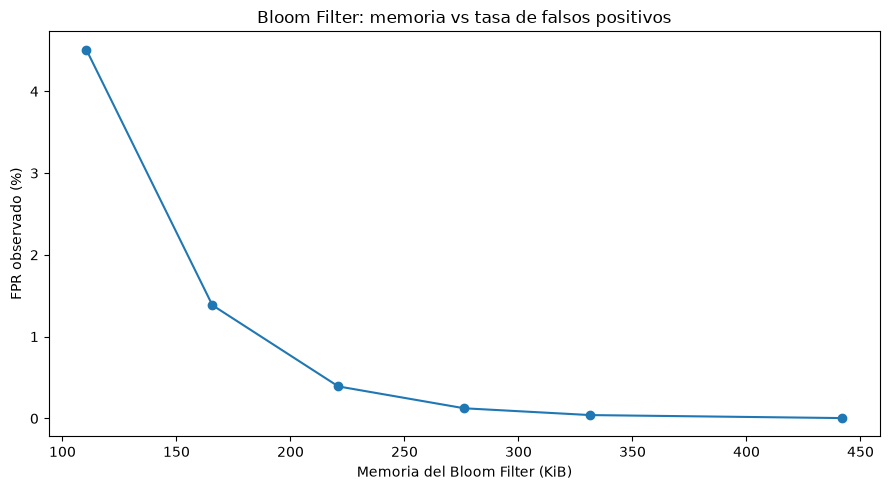

In [17]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    resultados_memoria_pd["memoria_kib"],
    resultados_memoria_pd["fpr_observado_pct"],
    marker="o"
)

ax.set_title("Bloom Filter: memoria vs tasa de falsos positivos")
ax.set_xlabel("Memoria del Bloom Filter (KiB)")
ax.set_ylabel("FPR observado (%)")

plt.tight_layout()
plt.show()

In [18]:
m_fijo = math.ceil(
    len(rucs_primera_aparicion) * 10
)

resultados_k = []

for k in [1, 3, 5, 7, 9, 11, 13]:

    resultado = evaluar_bloom(
        rucs_primera_aparicion,
        m_bits=m_fijo,
        k_hashes=k
    )

    resultados_k.append(resultado)

    print(
        f"k={k:2d} | "
        f"FP={resultado['fp']:5d} | "
        f"FPR obs={resultado['fpr_observado']*100:.4f}% | "
        f"FPR final teórico={resultado['fpr_teorico_final']*100:.4f}% | "
        f"tiempo={resultado['tiempo_s']:.2f}s"
    )

k= 1 | FP=10920 | FPR obs=4.8256% | FPR final teórico=9.5163% | tiempo=0.58s
k= 3 | FP= 1062 | FPR obs=0.4693% | FPR final teórico=1.7411% | tiempo=0.85s
k= 5 | FP=  399 | FPR obs=0.1763% | FPR final teórico=0.9431% | tiempo=0.85s
k= 7 | FP=  280 | FPR obs=0.1237% | FPR final teórico=0.8194% | tiempo=0.95s
k= 9 | FP=  316 | FPR obs=0.1396% | FPR final teórico=0.9127% | tiempo=1.44s
k=11 | FP=  364 | FPR obs=0.1609% | FPR final teórico=1.1650% | tiempo=1.34s
k=13 | FP=  477 | FPR obs=0.2108% | FPR final teórico=1.5980% | tiempo=1.49s


In [19]:
resultados_memoria_pd.to_csv(
    ARTIFACTS_DIR / "bloom_memoria.csv",
    index=False
)

resultados_k_pd = pd.DataFrame(resultados_k)

resultados_k_pd["fpr_observado_pct"] = (
    resultados_k_pd["fpr_observado"] * 100
)

resultados_k_pd["fpr_teorico_final_pct"] = (
    resultados_k_pd["fpr_teorico_final"] * 100
)

resultados_k_pd.to_csv(
    ARTIFACTS_DIR / "bloom_num_hashes.csv",
    index=False
)

### Conclusión

El Bloom Filter mostró el compromiso esperado entre memoria, precisión y tiempo.

Con 10 bits por elemento y 7 funciones hash se obtuvo un FPR observado de 0.1237% usando aproximadamente 276 KiB.

Al aumentar la memoria de 110.5 KiB a 442 KiB, el FPR observado disminuyó de 4.51% a 0.004%.

Manteniendo fija la memoria, el mejor resultado se obtuvo alrededor de k=7. Usar más funciones hash no continuó reduciendo el error y aumentó el tiempo de procesamiento.